# ***Building a Convolutional Neural Network with PyTorch***

*   ***2 Convolutional Layers***
> ***Same Padding (Same output size)***
*   ***2 Max Pooling Layers***
*   ***1 Max Connected layer***
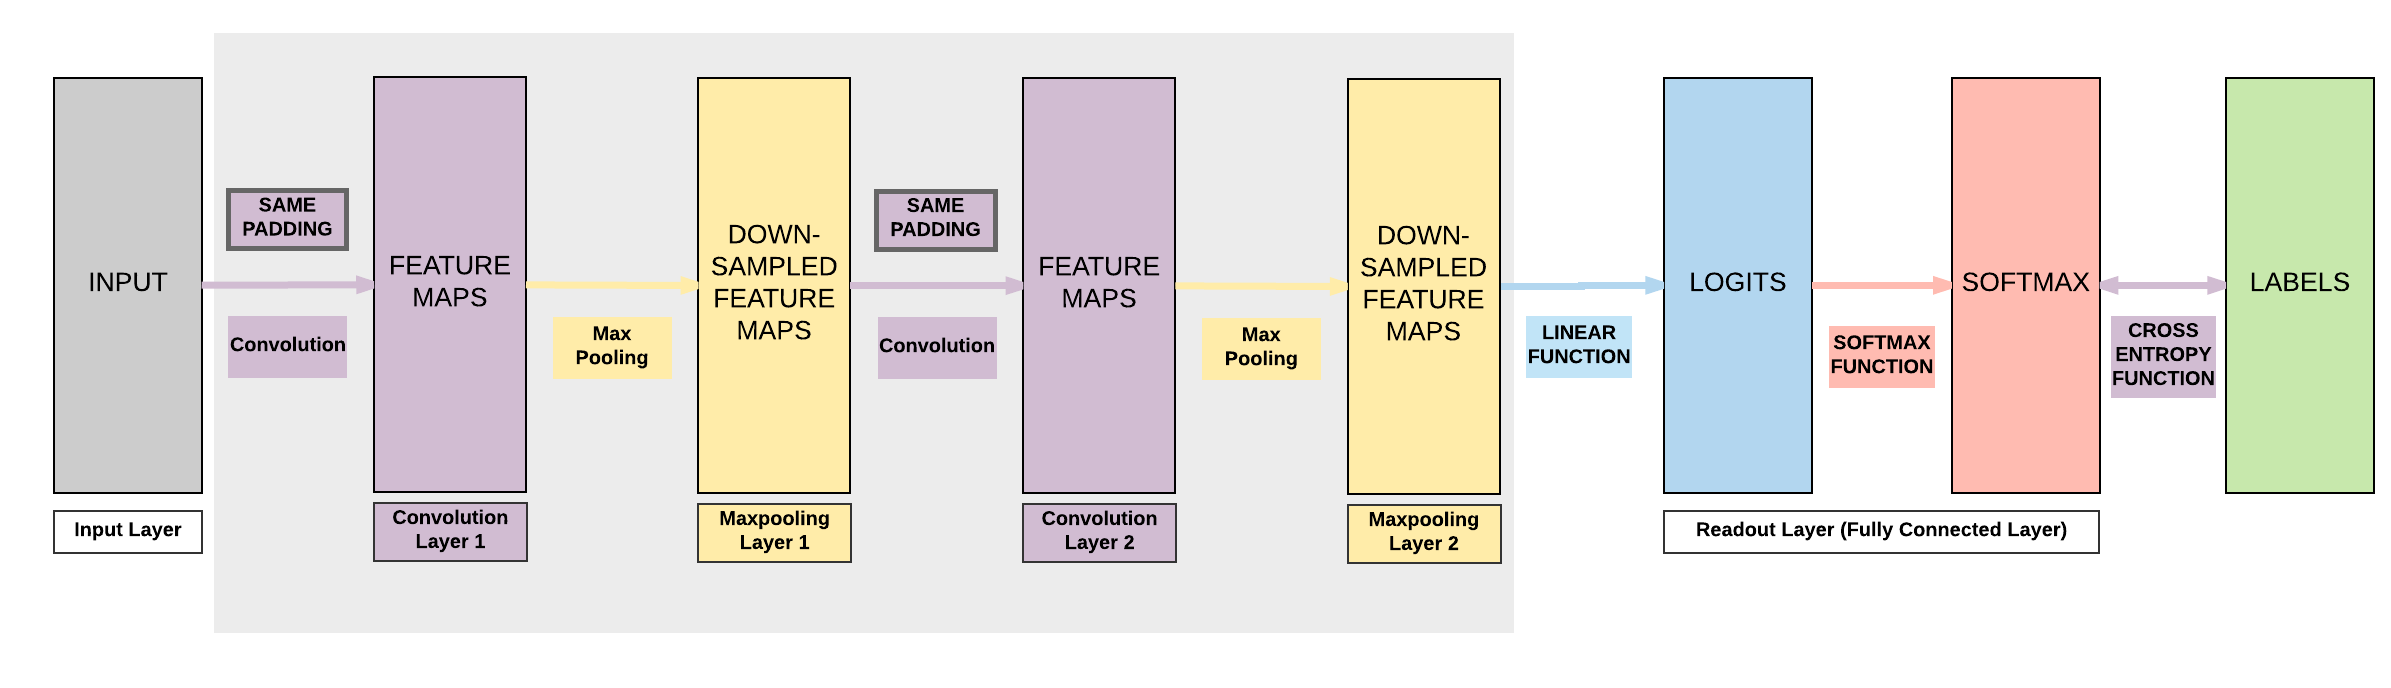

## *Step 1: Loading MNIST Train Dataset*


In [1]:
import torch
import torchvision
import torch.nn as nn
import torch.utils.data as Data
import matplotlib.pyplot as plt
from torch.autograd import Variable

In [2]:
train_dataset = torchvision.datasets.MNIST(root='./mnist', 
                            train=True, 
                            transform=torchvision.transforms.ToTensor(),
                            download=True)

test_dataset = torchvision.datasets.MNIST(root='./mnist', 
                           train=False, 
                           transform=torchvision.transforms.ToTensor())


  0%|          | 0/9912422 [00:00<?, ?it/s]

Extracting ./mnist/MNIST/raw/train-images-idx3-ubyte.gz to ./mnist/MNIST/raw



  0%|          | 0/28881 [00:00<?, ?it/s]

Extracting ./mnist/MNIST/raw/train-labels-idx1-ubyte.gz to ./mnist/MNIST/raw



  0%|          | 0/1648877 [00:00<?, ?it/s]

Extracting ./mnist/MNIST/raw/t10k-images-idx3-ubyte.gz to ./mnist/MNIST/raw



  0%|          | 0/4542 [00:00<?, ?it/s]

Extracting ./mnist/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./mnist/MNIST/raw



In [3]:
print(train_dataset.data.size())

torch.Size([60000, 28, 28])


In [4]:
print(train_dataset.targets.size())

torch.Size([60000])


In [5]:
print(test_dataset.data.size())

torch.Size([10000, 28, 28])


In [6]:
print(test_dataset.targets.size())

torch.Size([10000])


## *Step 2: Make Dataset Iterable*



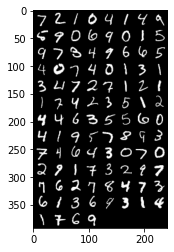

In [7]:
batch_size = 100
n_iters = 3000
num_epochs = n_iters / (len(train_dataset) / batch_size)
num_epochs = int(num_epochs)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, 
                                           batch_size=batch_size, 
                                           shuffle=True)

test_loader = torch.utils.data.DataLoader(dataset=test_dataset, 
                                          batch_size=batch_size, 
                                          shuffle=False)

# image visulization (you can try to check what other images look like)
images, label = next(iter(test_loader))
# images, label = next(iter(train_loader))
images_example = torchvision.utils.make_grid(images)
images_example = images_example.numpy().transpose(1,2,0) 
# mean = [0.1,0.2,0.5]   
# std = [0.5,0.5,0.5]
images_example = images_example #* std + mean  
plt.imshow(images_example )
plt.show()


## *Step 3: Create Model Class*
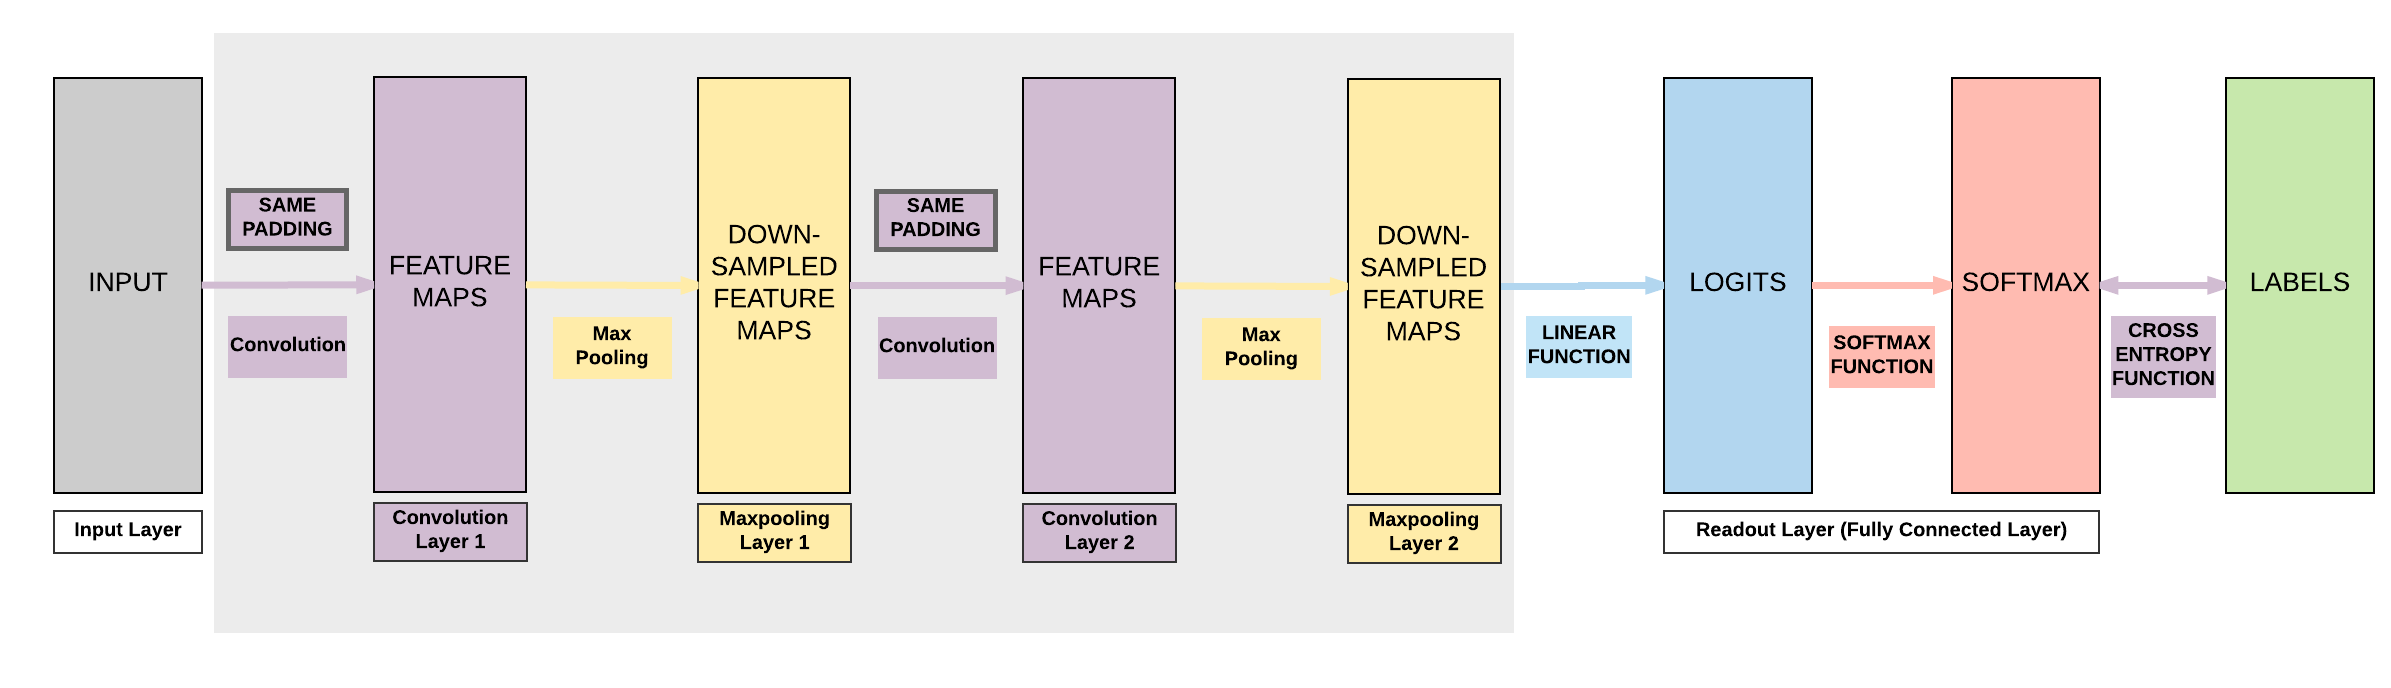

***Output Formula for Convolution:***

$O = \frac {W - K + 2P}{S} + 1$ \\

*   $O$: output height/length 
*   $W$: input height/lengt
*   $K$: **filter size (kernel size)**  = 5
*   $P$: same padding (non-zero)
> $P = \frac{K - 1}{2} = \frac{5 - 1}{2} = 2$
*   $S$: stride = 1

***Output Formula for Pooling:***


*   W: input height/width
*   K: **filter size = 2**
*   S: **stride size = filter size**, PyTorch defaults the stride to kernel filter size
> If using PyTorch default stride, this will result in the formula $O = \frac {W}{K}$

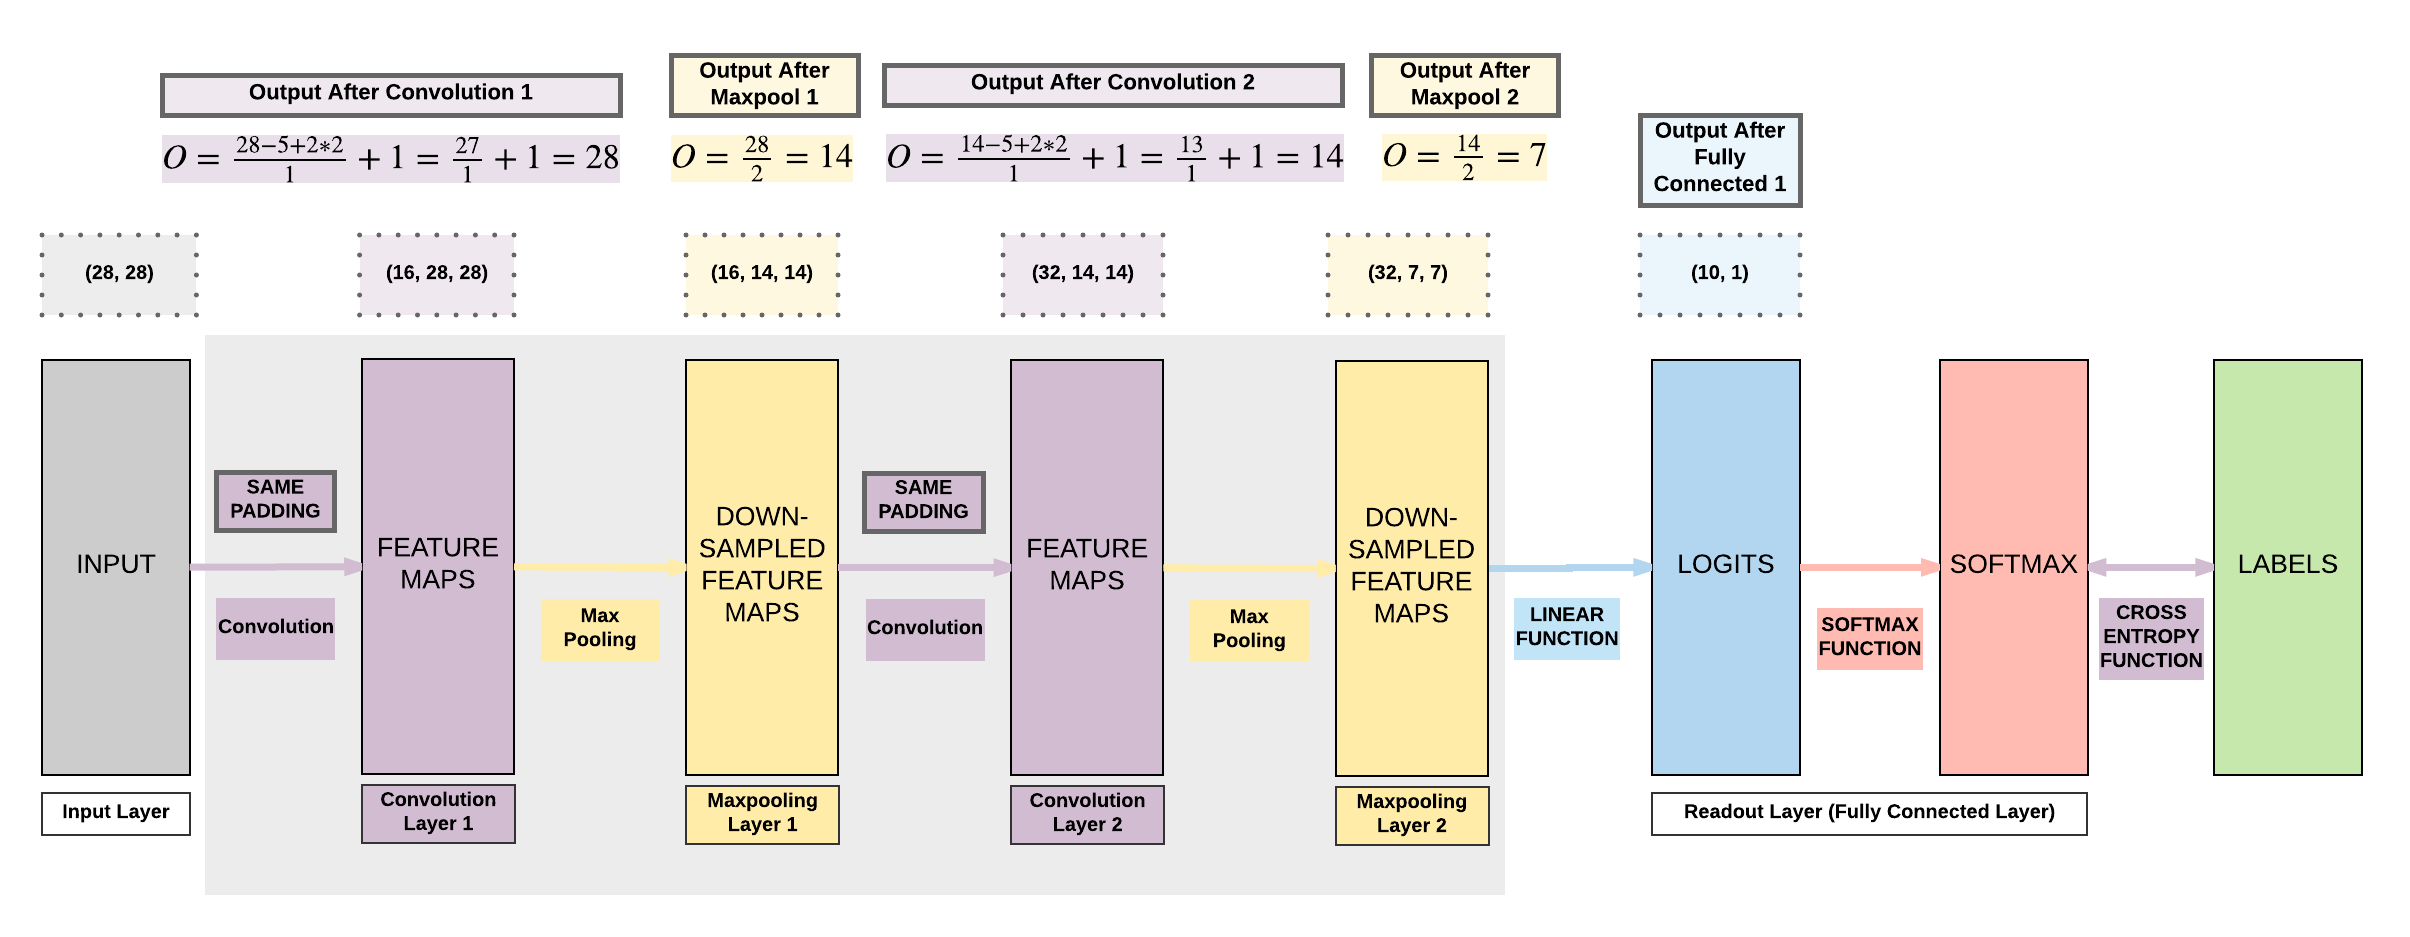

In [8]:
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        
        # Convolution 1
        self.cnn1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=5, stride=1, padding=2)
        self.relu1 = nn.ReLU()
        
        # Max pool 1
        self.maxpool1 = nn.MaxPool2d(kernel_size=2)
     
        # Convolution 2
        self.cnn2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5, stride=1, padding=2)
        self.relu2 = nn.ReLU()
        
        # Max pool 2
        self.maxpool2 = nn.MaxPool2d(kernel_size=2)
        
        # Fully connected 1 (readout)
        self.fc1 = nn.Linear(32 * 7 * 7, 10) 
    
    def forward(self, x):
        # Convolution 1
        out = self.cnn1(x)
        out = self.relu1(out)
        
        # Max pool 1
        out = self.maxpool1(out)
        
        # Convolution 2 
        out = self.cnn2(out)
        out = self.relu2(out)
        
        # Max pool 2 
        out = self.maxpool2(out)
        
        # Resize
        # Original size: (100, 32, 7, 7)
        # out.size(0): 100
        # New out size: (100, 32*7*7)
        out = out.view(out.size(0), -1)

        # Linear function (readout)
        out = self.fc1(out)
        
        return out

## *Step 4: Instantite Model Class*

In [9]:
print(torch.cuda.is_available())
model = CNNModel()

if torch.cuda.is_available():
  model = model.cuda()

True


## *Step 5: Instantiate Loss Class*

*   Convolutional Neural Network: **Cross Entropy Loss**
> Feedforward Neural Network: **Cross Entropy Loss**
> Logistic Regression: **Cross Entropy Loss**
> Linear Regression: **MSE**


In [10]:
criterion = nn.CrossEntropyLoss()

## *Step 6: Instantiate Optimizer Class*

*  Simplified equation
> $\theta = \theta - \eta \cdot \nabla_\theta$ \\
> $\theta$: parameters \\
> $\eta$: learning rate (how fast we want to learn) \\
> $\nabla_\theta$: parameters' gradients


*   Even simplier equation
> parameters = parameters - learning_rate * parameters_gradients \\
> At every iteration, model's parameters are updated

In [11]:
learning_rate = 0.01

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)  

## *Parameters In-Depth*

In [12]:
print(model)

CNNModel(
  (cnn1): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (relu1): ReLU()
  (maxpool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (cnn2): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (relu2): ReLU()
  (maxpool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=10, bias=True)
)


In [13]:
print(model.parameters())

print(len(list(model.parameters())))

# Convolution 1: 16 Kernels
print(list(model.parameters())[0].size())

# Convolution 1 Bias: 16 Kernels
print(list(model.parameters())[1].size())

# Convolution 2: 32 Kernels with depth = 16
print(list(model.parameters())[2].size())

# Convolution 2 Bias: 32 Kernels with depth = 16
print(list(model.parameters())[3].size())

# Fully Connected Layer 1
print(list(model.parameters())[4].size())

# Fully Connected Layer Bias
print(list(model.parameters())[5].size())

<generator object Module.parameters at 0x7fe7c58af580>
6
torch.Size([16, 1, 5, 5])
torch.Size([16])
torch.Size([32, 16, 5, 5])
torch.Size([32])
torch.Size([10, 1568])
torch.Size([10])


## *Step 7: Train Model*

*   **Process**
1.   Convert inputs to tensors with gradient accumulation abilities
> CNN Input: (1, 28, 28) \\
> Feedforward NN Input: (1, 28*28)
2.   Clear gradient buffets
3.   Get output given inputs
4.   Get loss
5.   Get gradients w.r.t. parameters
6.   Update parameters using gradients
> parameters = parameters - learning_rate * parameters_gradients
7.   REPEAT

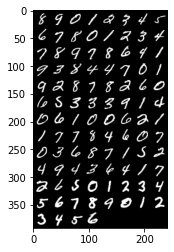

Iteration: 500. Outputs: tensor([8, 9, 0, 1, 4, 9, 4, 5, 6, 7, 8, 0, 1, 2, 3, 4, 7, 8, 9, 7, 8, 6, 4, 1,
        9, 8, 8, 4, 4, 7, 0, 1, 9, 2, 8, 7, 8, 2, 6, 0, 6, 6, 3, 5, 8, 9, 1, 4,
        0, 6, 1, 0, 0, 0, 2, 1, 1, 7, 7, 3, 4, 6, 0, 7, 0, 3, 6, 8, 7, 1, 3, 2,
        4, 9, 4, 2, 6, 4, 1, 7, 3, 6, 6, 0, 1, 2, 3, 4, 5, 6, 7, 8, 4, 0, 1, 2,
        3, 4, 5, 6], device='cuda:0').  Loss: 0.43928107619285583. Accuracy: 90.79999542236328. Total: 10000. Correct: 9080


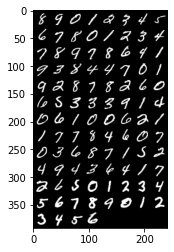

Iteration: 1000. Outputs: tensor([8, 9, 0, 1, 2, 9, 4, 5, 6, 7, 8, 0, 1, 2, 3, 4, 7, 8, 9, 7, 8, 6, 4, 1,
        9, 3, 8, 4, 4, 7, 0, 1, 9, 2, 8, 7, 8, 2, 6, 0, 6, 6, 3, 8, 8, 9, 1, 4,
        0, 6, 1, 0, 0, 6, 2, 1, 1, 7, 7, 8, 4, 6, 0, 7, 0, 3, 6, 8, 7, 1, 3, 2,
        4, 9, 4, 2, 6, 4, 1, 7, 3, 6, 6, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2,
        3, 4, 5, 6], device='cuda:0').  Loss: 0.2869761884212494. Accuracy: 93.58999633789062. Total: 10000. Correct: 9359


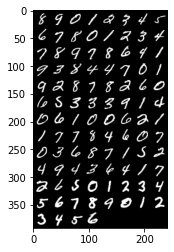

Iteration: 1500. Outputs: tensor([8, 9, 0, 1, 3, 7, 4, 5, 6, 7, 8, 0, 1, 2, 3, 4, 7, 8, 9, 7, 8, 6, 4, 1,
        9, 3, 8, 4, 4, 7, 0, 1, 9, 2, 8, 7, 8, 2, 6, 0, 6, 5, 3, 8, 8, 9, 1, 4,
        0, 6, 1, 0, 0, 6, 2, 1, 1, 7, 7, 1, 4, 6, 0, 7, 0, 3, 6, 8, 7, 1, 3, 2,
        4, 9, 4, 3, 6, 4, 1, 7, 3, 6, 6, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2,
        3, 4, 5, 6], device='cuda:0').  Loss: 0.16554796695709229. Accuracy: 94.7699966430664. Total: 10000. Correct: 9477


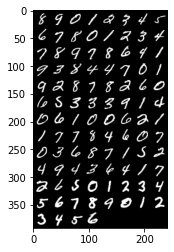

Iteration: 2000. Outputs: tensor([8, 9, 0, 1, 2, 7, 4, 5, 6, 7, 8, 0, 1, 2, 3, 4, 7, 8, 9, 7, 8, 6, 4, 1,
        9, 3, 8, 4, 4, 7, 0, 1, 9, 2, 8, 7, 8, 2, 6, 0, 6, 5, 3, 8, 8, 9, 1, 4,
        0, 6, 1, 0, 0, 6, 2, 1, 1, 7, 7, 8, 4, 6, 0, 7, 0, 3, 6, 8, 7, 1, 3, 2,
        4, 9, 4, 3, 6, 4, 1, 7, 3, 6, 6, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2,
        3, 4, 5, 6], device='cuda:0').  Loss: 0.1283469945192337. Accuracy: 95.48999786376953. Total: 10000. Correct: 9549


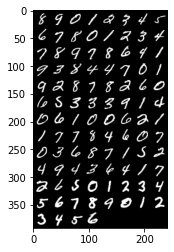

Iteration: 2500. Outputs: tensor([8, 9, 0, 1, 2, 9, 4, 5, 6, 7, 8, 0, 1, 2, 3, 4, 7, 8, 9, 7, 8, 6, 4, 1,
        9, 3, 8, 4, 4, 7, 0, 1, 9, 2, 8, 7, 8, 2, 6, 0, 6, 5, 3, 3, 8, 9, 1, 4,
        0, 6, 1, 0, 0, 6, 2, 1, 1, 7, 7, 8, 4, 6, 0, 7, 0, 3, 6, 8, 7, 1, 3, 2,
        4, 9, 4, 3, 6, 4, 1, 7, 3, 6, 6, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2,
        3, 4, 5, 6], device='cuda:0').  Loss: 0.11641726642847061. Accuracy: 96.12999725341797. Total: 10000. Correct: 9613


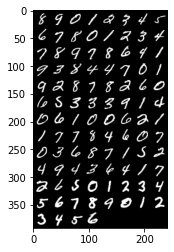

Iteration: 3000. Outputs: tensor([8, 9, 0, 1, 2, 9, 4, 5, 6, 7, 8, 0, 1, 2, 3, 4, 7, 8, 9, 7, 8, 6, 4, 1,
        9, 3, 8, 4, 4, 7, 0, 1, 9, 2, 8, 7, 8, 2, 6, 0, 6, 5, 3, 3, 8, 9, 1, 4,
        0, 6, 1, 0, 0, 6, 2, 1, 1, 7, 7, 8, 4, 6, 0, 7, 0, 3, 6, 8, 7, 1, 5, 2,
        4, 9, 4, 3, 6, 4, 1, 7, 2, 6, 6, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2,
        3, 4, 5, 6], device='cuda:0').  Loss: 0.12125951796770096. Accuracy: 96.56999969482422. Total: 10000. Correct: 9657


In [14]:
iter = 0
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):

        # Load images
        images = images.requires_grad_()

        # Use GPU if it is available
        if torch.cuda.is_available():
          images = images.cuda()
          labels = labels.cuda()
        
        # Clear gradients w.r.t. parameters
        optimizer.zero_grad()
        
        # Forward pass to get output/logits
        outputs = model(images)
        
        # Calculate Loss: softmax --> cross entropy loss
        loss = criterion(outputs, labels)
        
        # Getting gradients w.r.t. parameters
        loss.backward()
        
        # Updating parameters
        optimizer.step()
        
        iter += 1
        
        if iter % 500 == 0:
            # Calculate Accuracy         
            correct = 0
            total = 0
            # Iterate through test dataset
            for images, labels in test_loader:

                
                # Load images
                images = images.requires_grad_()

                # Use GPU if it is available
                if torch.cuda.is_available():
                  images = images.cuda()
                  labels = labels.cuda()

                # Forward pass only to get logits/output
                outputs = model(images)

                # Get predictions from the maximum value
                _, predicted = torch.max(outputs.data, 1)
              
                
                # Total number of labels
                total += labels.size(0)
                
                # Total correct predictions
                correct += (predicted == labels).sum()
            
            accuracy = 100 * correct / total
            
            # image visulization: try to compare the classification results with the test image, you can try to distract other more images
            images_test = torchvision.utils.make_grid(images)

            # Send images to CPU if we used GPU before
            if torch.cuda.is_available():
              images_test = images_test.cpu()

            images_test = images_test.numpy().transpose(1,2,0) 

            plt.imshow(images_test)
            plt.show()
            # Print output information
            print('Iteration: {}. Outputs: {}.  Loss: {}. Accuracy: {}. Total: {}. Correct: {}'.format(iter, predicted, loss.item(), accuracy, total, correct))
           

## *Step 8: Test Model*

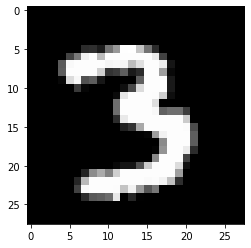

The identified number is 3


In [15]:
# Change model to evaluate mode
model.eval()

# Disable gradient calculation
with torch.no_grad():
    # Visualize the image, Change number from 1-10000
    test_image = test_dataset.data[500, :, :]
    test_image = test_image[None, None, :, :]
    visual_image = torchvision.utils.make_grid(test_image)
    visual_image = visual_image.numpy().transpose(1,2,0) 
    plt.imshow(visual_image)
    plt.show()

    # Predict the number
    test_image_tensor = test_image.type(torch.FloatTensor)
    if torch.cuda.is_available():
      test_image_tensor = test_image_tensor.cuda()

    test_output = model(test_image_tensor)

    # Get predictions from the maximum value
    _, predicted = torch.max(test_output.data, 1)

    # Print the number
    print("The identified number is %d"%predicted)

    #out_data = model(data)

## *Step 9: Test your own handwriting!*

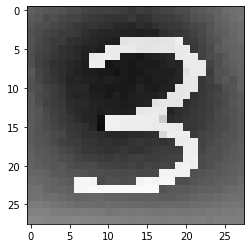

The identified number is 3


In [17]:
# Make changes to this step as you see fit and to see if you can use the model to recognize your own handwritten digits
# If you are using Google Colab: First, you need to upload your image to the Google Colab files. You can find it on the left side of the page
import numpy as np
import cv2

# Load an image file
image = cv2.imread('Sample_image.JPG')

# Here are some sample processing to the image to 
# make it the same format as the training and testing images. 
# You may have to use your own way to process it so that the 
# image follow the format of training/testing images

## Resize the image
resized_image = cv2.resize(image, (28, 28))
# Convert the image to grayscale
gray_image = cv2.cvtColor(resized_image, cv2.COLOR_BGR2GRAY)
# Invert the color
gray_image = 255 - gray_image

# Change model to evaluate mode
model.eval()

# Disable gradient calculation
with torch.no_grad():
    # Visualize the image
    test_image = torch.tensor(gray_image)
    test_image = test_image[None, None, :, :]
    visual_image = torchvision.utils.make_grid(test_image)
    visual_image = visual_image.numpy().transpose(1,2,0) 
    plt.imshow(visual_image)
    plt.show()

    # Predict the number
    test_image_tensor = test_image.type(torch.FloatTensor)
    if torch.cuda.is_available():
      test_image_tensor = test_image_tensor.cuda()

    test_output = model(test_image_tensor)

    # Get predictions from the maximum value
    _, predicted = torch.max(test_output.data, 1)

    # Print the number
    print("The identified number is %d"%predicted)

    #out_data = model(data)